## Класифікація цін на житло в Каліфорнії

In [23]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [24]:

housing = fetch_california_housing()

X = housing.data
y = housing.target

print("Розмір набору даних:", X.shape)
print("Кількість цільових значень:", len(y))
print("Перші 5 цін:", y[:5])

Розмір набору даних: (20640, 8)
Кількість цільових значень: 20640
Перші 5 цін: [4.526 3.585 3.521 3.413 3.422]


In [25]:

median_price = np.median(y)


y_class = (y > median_price).astype(int)

print("Медіанна ціна:", median_price)
print("Кількість об'єктів класу 0:", np.sum(y_class == 0))
print("Кількість об'єктів класу 1:", np.sum(y_class == 1))

Медіанна ціна: 1.797
Кількість об'єктів класу 0: 10323
Кількість об'єктів класу 1: 10317


In [26]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)


model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)

print("Модель успішно навчена!")

Навчальна вибірка: (16512, 8)
Тестова вибірка: (4128, 8)
Модель успішно навчена!


c:\Users\User\jupyter\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


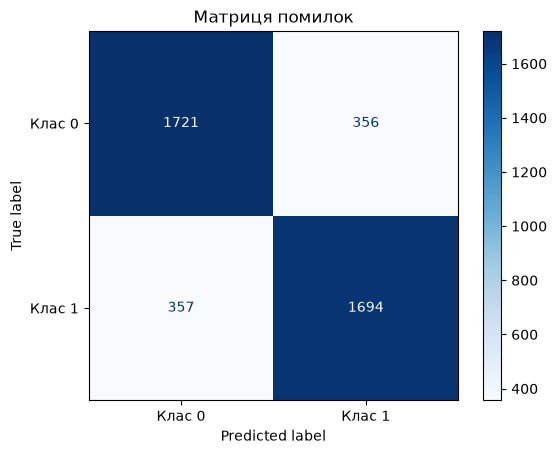

In [27]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Клас 0", "Клас 1"]
)

display.plot(cmap="Blues")
plt.title("Матриця помилок")
plt.show()

In [28]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Точність:  {accuracy:.4f}")
print(f"Влучність: {precision:.4f}")
print(f"Повнота:    {recall:.4f}")
print(f"F1-міра:  {f1:.4f}")

Точність:  0.8273
Влучність: 0.8263
Повнота:    0.8259
F1-міра:  0.8261
